A test to figure out what's going on with the rotate feature.

In [1]:
import openmc as omc


mat1=omc.Material()
mat1.add_element('H',1)

mat2=omc.Material()
mat2.add_element('Li',1)

material=omc.Materials([mat1,mat2])
material.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
material.export_to_xml()

# Surface definitions
s1 = omc.XCylinder(r=1,surface_id=1)


c1 = omc.Cell(cell_id=1,fill=mat1,region=-s1)
c2 = omc.Cell(cell_id=2,fill=mat2,region=(-s1).rotate([[40,130,90],[50,40,90],[90,90,0]]))

geometry = omc.Geometry([c1,c2])
geometry.export_to_xml()

In [2]:
settings = omc.Settings()
settings.export_to_xml()
#omc.run(output=1)

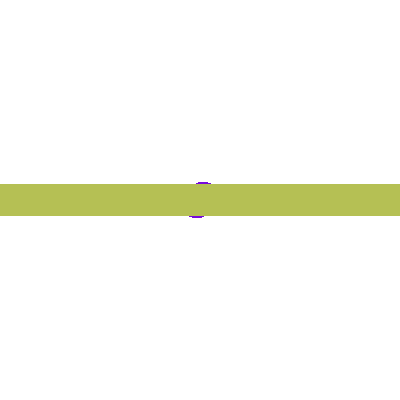

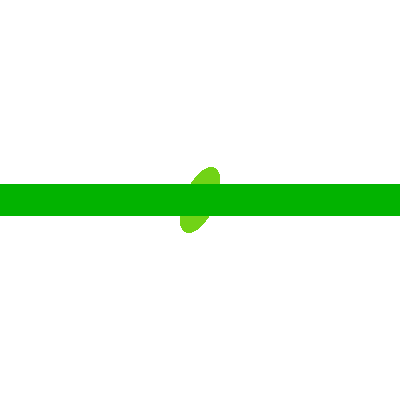

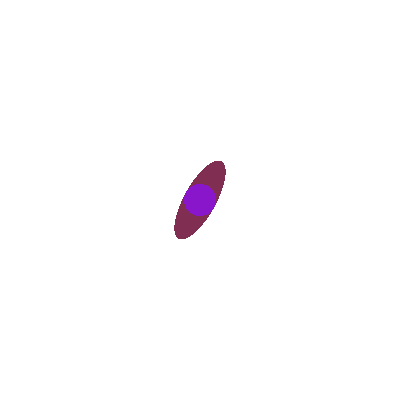

In [3]:
w = 25
plots = omc.Plots()

plot = omc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
#plot.universe=1
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = omc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
#plot.universe=1
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = omc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
#plot.universe=1
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

omc.plot_inline(plots)
